https://github.com/iandriyash/ai-arhictect-2026-demo

# Промежуточная аттестация 2
## Банковский сектор: прогноз просрочки по розничному кредиту

**Продолжение аттестации 1.** Витрина `loan_overdue_mart.csv`, целевая `is_overdue` — был ли по кредиту хотя бы один платёж с просрочкой.

**Задача.** Бинарная классификация: оценить риск просрочки на момент выдачи кредита. Практическая ценность — скоринг: банк видит риск до выдачи и может усилить проверку, запросить дополнительные документы или передать заявку на ручное рассмотрение.

**Зачем это банку.** Модель работает в момент подачи заявки, до выдачи кредита, и применяется к любой новой заявке — в том числе от человека, у которого в банке ещё не было кредитов. Кредиты витрины — это обучающая история: по ним уже известно, была ли просрочка. Пользователь — отдел проверки заявок. Дешёвые действия вроде СМС-напоминаний банк делает для всех, а дорогие — ручную проверку, запрос документов, подбор условий, звонок перед первым платежом — для всех сделать нельзя. Модель помогает решить, на ком их сосредоточить.

В реальном банке решение по заявке принимается цепочкой: жёсткие правила и антифрод, данные кредитного бюро, долговая нагрузка по всем кредитам, внутренний скоринг по анкете, стратегия (одобрить ли, лимит, ставка, нужна ли ручная проверка). Эта модель — блок внутреннего скоринга. Её роль — маршрутизация заявок по глубине проверки, а не самостоятельное решение «да / нет».

**Признаки.** Только то, что известно при выдаче: доход, возраст, ставка, срок, сумма, продукт, статус занятости, отношение суммы к доходу (`loan_to_income` = сумма / доход). Признаки «из будущего» (`payments_cnt`, `late_cnt`, `late_fee_sum`) в модели не входят — это утечка, зафиксированная в аттестации 1. Восемь кредитов с нулевым доходом исключены: для них отношение суммы к доходу не определено (в аттестации 1 они оставались в витрине с флагом, здесь это 0.3% строк).

**Связь с аттестацией 1.** В аттестации 1 показано, что цель накапливается с длиной наблюдения: чем больше платежей успело пройти, тем выше шанс хотя бы одной просрочки (от 7.3% у кредитов с одним платежом до 37.4% с десятью). По итогам аттестации 1 преподаватель рекомендовал попробовать использовать признаки «из будущего» и горизонт наблюдения в моделях. Это сделано в двух шагах. В разделе 5.3 — диагностика: какую часть сигнала в цели даёт сам горизонт. В разделе 5.4 — модель, где `late_cnt` и `payments_cnt` задают цель и экспозицию, а не входы: она даёт вероятность просрочки за фиксированный срок. Входом модели `payments_cnt` не служит — при выдаче кредита число будущих платежей неизвестно.

**Разбиение.** 60% обучающая / 20% оценка качества (eval) / 20% прогноз (forecast). Таргет второй половины в работе не используется до раздела 8, где он нужен только для контроля.

## 1. Загрузка и подготовка

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score,
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
np.random.seed(42)


def auc_se(auc, n_pos, n_neg):
    """Стандартная ошибка ROC-AUC (формула Хэнли — Макнила)."""
    q1 = auc / (2 - auc)
    q2 = 2 * auc**2 / (1 + auc)
    return np.sqrt((auc * (1 - auc) + (n_pos - 1) * (q1 - auc**2) + (n_neg - 1) * (q2 - auc**2)) / (n_pos * n_neg))


df = pd.read_csv("loan_overdue_mart.csv")
print("Строк:", len(df))
print(df["is_overdue"].value_counts(normalize=True).round(3))

Строк: 2477
is_overdue
0   0.794
1   0.206
Name: proportion, dtype: float64


In [2]:
features = [
    "annual_income", "customer_age", "interest_rate", "term_months",
    "principal_amount", "loan_product_id", "employment_status_id", "loan_to_income",
]
work = df[features + ["is_overdue"]].dropna().copy()
work["product_2"] = (work["loan_product_id"] == 2).astype(int)
work["emp_2"] = (work["employment_status_id"] == 2).astype(int)
feature_cols = [
    "annual_income", "customer_age", "interest_rate", "term_months",
    "principal_amount", "loan_to_income", "product_2", "emp_2",
]
print("После очистки:", len(work))
print(f"Исключено строк: {len(df) - len(work)} (у них annual_income = 0, поэтому loan_to_income не определён)")
print("Признаки:", feature_cols)

После очистки: 2469
Исключено строк: 8 (у них annual_income = 0, поэтому loan_to_income не определён)
Признаки: ['annual_income', 'customer_age', 'interest_rate', 'term_months', 'principal_amount', 'loan_to_income', 'product_2', 'emp_2']


### 1.1 Наблюдения о связи переменных с просрочкой

Задача сформулирована на основе наблюдений о том, как просрочка связана с переменными. Ниже они пересчитаны на очищенной витрине.

- Просрочка бывает у каждого пятого кредита (20.6%): классы несбалансированы.
- **Статус занятости 2** — просрочка 28.9% против 19.6% у остальных (263 кредита).
- **Доход** — просрочка заметно ниже только в верхнем квартиле дохода (14.9%); в трёх остальных квартилях она 21–24%.
- **Продукт** просрочку не различает: 20.7% и 20.4%.

Из этого следует ожидание: сигнал в признаках слабый, сосредоточен в доходе и статусе занятости, поэтому ценность модели — в ранжировании заявок по риску, а не в автоматическом решении «выдать / не выдать».

In [3]:
print(f"Доля просрочек: {work['is_overdue'].mean():.1%}  (кредитов: {len(work)})\n")

obs_emp = work.groupby("emp_2")["is_overdue"].agg(["mean", "count"])
obs_emp.index = ["статус занятости не 2", "статус занятости 2"]
print(obs_emp.rename(columns={"mean": "доля просрочек", "count": "кредитов"}).to_string())
med_inc = work.groupby("emp_2")["annual_income"].median()
print(f"Медианный доход: статус занятости 2 — {med_inc[1]:,.0f}, остальные — {med_inc[0]:,.0f}\n")

income_q = pd.qcut(work["annual_income"], 4, labels=["Q1 (низкий)", "Q2", "Q3", "Q4 (высокий)"])
print(f"Верхний квартиль дохода начинается с {work['annual_income'].quantile(0.75):,.0f}\n")
obs_inc = work.groupby(income_q, observed=True)["is_overdue"].agg(["mean", "count"])
print(obs_inc.rename(columns={"mean": "доля просрочек", "count": "кредитов"}).to_string(), "\n")

obs_prod = work.groupby("product_2")["is_overdue"].agg(["mean", "count"])
obs_prod.index = ["продукт 1", "продукт 2"]
print(obs_prod.rename(columns={"mean": "доля просрочек", "count": "кредитов"}).to_string())

Доля просрочек: 20.6%  (кредитов: 2469)

                       доля просрочек  кредитов
статус занятости не 2           0.196      2206
статус занятости 2              0.289       263
Медианный доход: статус занятости 2 — 2,750,852, остальные — 1,906,522

Верхний квартиль дохода начинается с 2,766,986

               доля просрочек  кредитов
annual_income                          
Q1 (низкий)             0.214       618
Q2                      0.238       618
Q3                      0.222       616
Q4 (высокий)            0.149       617 

           доля просрочек  кредитов
продукт 1           0.207      1497
продукт 2           0.204       972


Сигнал в статусе занятости 2 и в верхнем квартиле дохода.

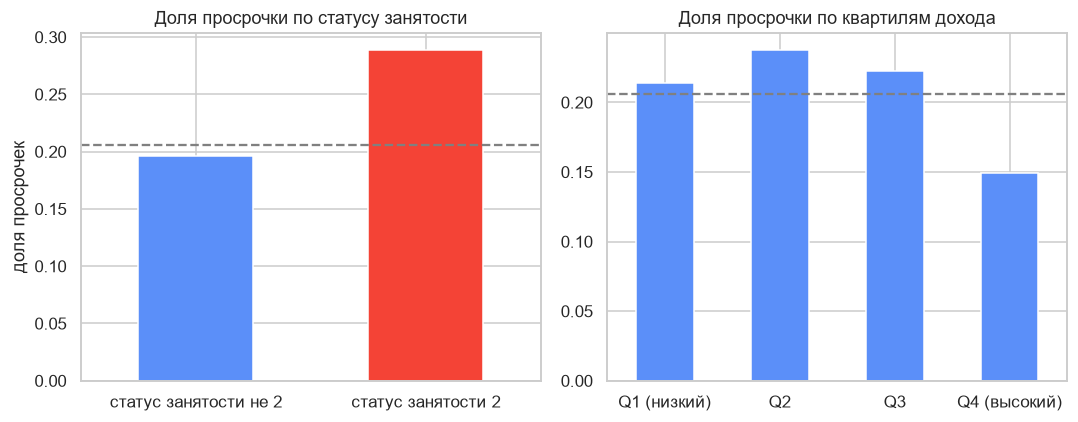

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

obs_emp["mean"].plot.bar(ax=axes[0], color=["#5B8FF9", "#F44336"], edgecolor="white")
axes[0].axhline(work["is_overdue"].mean(), color="gray", ls="--")
axes[0].set_title("Доля просрочки по статусу занятости")
axes[0].set_ylabel("доля просрочек")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)

obs_inc["mean"].plot.bar(ax=axes[1], color="#5B8FF9", edgecolor="white")
axes[1].axhline(work["is_overdue"].mean(), color="gray", ls="--")
axes[1].set_title("Доля просрочки по квартилям дохода")
axes[1].set_ylabel("")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

Распределения дохода по классам сильно перекрываются.

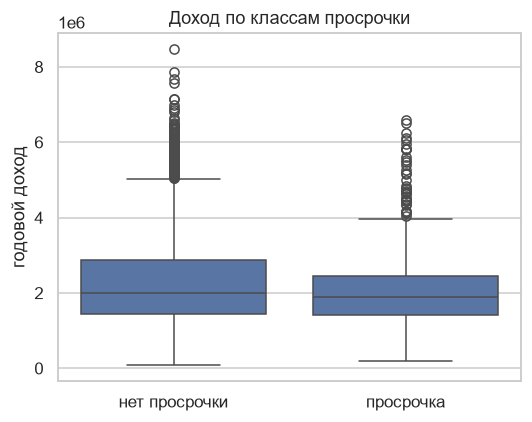

In [5]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.boxplot(data=work, x="is_overdue", y="annual_income", ax=ax)
ax.set_xticks([0, 1])
ax.set_xticklabels(["нет просрочки", "просрочка"])
ax.set_title("Доход по классам просрочки")
ax.set_xlabel("")
ax.set_ylabel("годовой доход")
plt.tight_layout()
plt.show()

## 2. Разбиение 60 / 20 / 20

Сначала отделяем 40% на тест. Затем тест делим пополам: 20% на оценку качества (eval, таргет известен) и 20% на прогноз (forecast). Стратификация по `is_overdue`, `random_state=42`.

Таргет второй половины сохраняется отдельно в переменной `y_forecast_hidden` и до раздела 8 не используется: ни для обучения, ни для выбора модели, набора переменных и порога. Модель получает на forecast только признаки.

In [6]:
X = work[feature_cols]
y = work["is_overdue"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=42, stratify=y
)
X_eval, X_forecast, y_eval, y_forecast_hidden = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)
# y_forecast_hidden — «скрытый» таргет второй половины: до раздела 8 не используется ни в обучении,
# ни в выборе модели, ни в прогнозе (на практике этих значений у нас бы не было).

print(f"Train: {len(X_train)} ({len(X_train)/len(work):.0%})")
print(f"Eval:  {len(X_eval)} ({len(X_eval)/len(work):.0%})")
print(f"Forecast: {len(X_forecast)} ({len(X_forecast)/len(work):.0%})")
print(f"Доля 1 — train {y_train.mean():.3f}, eval {y_eval.mean():.3f}")

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_eval_s = scaler.transform(X_eval)
X_forecast_s = scaler.transform(X_forecast)

Train: 1481 (60%)
Eval:  494 (20%)
Forecast: 494 (20%)
Доля 1 — train 0.206, eval 0.206


## 3. Обучение моделей

Пять моделей: логистическая регрессия, дерево решений, случайный лес, градиентный бустинг и KNN (метод ближайших соседей). Гиперпараметры заданы фиксированно, без подбора: при слабом сигнале и 1481 строке в train подбор скорее подгонит модель под шум. Проверка подбором по кросс-валидации — в разделе 4.1. Масштабирование обучается только на train.

In [7]:
models = {
    "Логит": LogisticRegression(max_iter=1000, random_state=42),
    "Дерево": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Случайный лес": RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42),
    "Бустинг": GradientBoostingClassifier(n_estimators=150, max_depth=3, learning_rate=0.1, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=15),
}

fitted = {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    fitted[name] = model
    print(f"{name}: обучена")

Логит: обучена
Дерево: обучена
Случайный лес: обучена
Бустинг: обучена
KNN: обучена


## 4. Оценка качества на первых 20% (eval)

Таргет известен. Считаем ROC-AUC по вероятностям, остальные метрики при пороге 0.5 и при пороге, подобранном по F1 на eval.

In [8]:
def metrics_at(name, y_true, proba, thr):
    pred = (proba >= thr).astype(int)
    return {
        "модель": name,
        "порог": thr,
        "ROC-AUC": roc_auc_score(y_true, proba),
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "помечено 1": int(pred.sum()),
    }

rows_05 = []
rows_best = []
probas_eval = {}
for name, model in fitted.items():
    proba = model.predict_proba(X_eval_s)[:, 1]
    probas_eval[name] = proba
    rows_05.append(metrics_at(name, y_eval, proba, 0.5))
    thresholds = np.round(np.arange(0.10, 0.50, 0.01), 2)
    f1s = [f1_score(y_eval, (proba >= t).astype(int), zero_division=0) for t in thresholds]
    best_thr = thresholds[int(np.argmax(f1s))]
    rows_best.append(metrics_at(name, y_eval, proba, best_thr))

eval_05 = pd.DataFrame(rows_05).sort_values("ROC-AUC", ascending=False)
eval_best = pd.DataFrame(rows_best).sort_values("F1", ascending=False)
print("При пороге 0.5:")
display(eval_05.round(3))
print("При пороге с лучшим F1:")
display(eval_best.round(3))

При пороге 0.5:


,модель,порог,ROC-AUC,Accuracy,Precision,Recall,F1,помечено 1
0,Логит,0.500,0.588,0.794,0.000,0.000,0.000,0
4,KNN,0.500,0.583,0.800,1.000,0.029,0.057,3
2,Случайный лес,0.500,0.554,0.794,0.000,0.000,0.000,0
3,Бустинг,0.500,0.540,0.763,0.059,0.010,0.017,17
1,Дерево,0.500,0.521,0.783,0.000,0.000,0.000,5


При пороге с лучшим F1:


,модель,порог,ROC-AUC,Accuracy,Precision,Recall,F1,помечено 1
0,Логит,0.170,0.588,0.360,0.236,0.941,0.378,406
2,Случайный лес,0.180,0.554,0.407,0.241,0.873,0.378,369
1,Дерево,0.170,0.521,0.354,0.233,0.931,0.373,407
3,Бустинг,0.130,0.540,0.381,0.226,0.824,0.354,372
4,KNN,0.100,0.583,0.350,0.219,0.833,0.346,389


Ни одна сложная модель не лучше логита; дерево и бустинг ниже него.

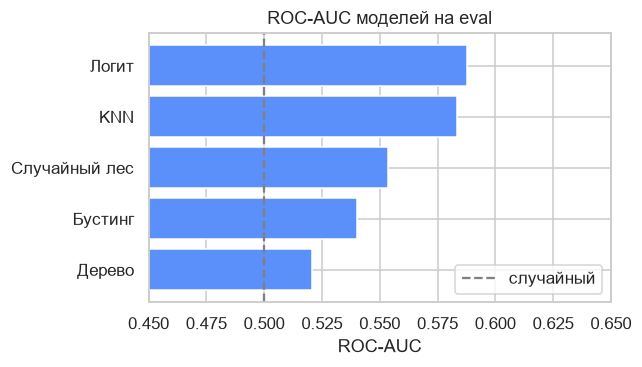

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.5))
order = eval_05.sort_values("ROC-AUC")
ax.barh(order["модель"], order["ROC-AUC"], color="#5B8FF9")
ax.axvline(0.5, color="gray", ls="--", label="случайный")
ax.set_xlim(0.45, 0.65)
ax.set_title("ROC-AUC моделей на eval")
ax.set_xlabel("ROC-AUC")
ax.legend()
plt.tight_layout()
plt.show()

ROC-кривые почти совпадают: сложные модели не дают заметного прироста над логитом.

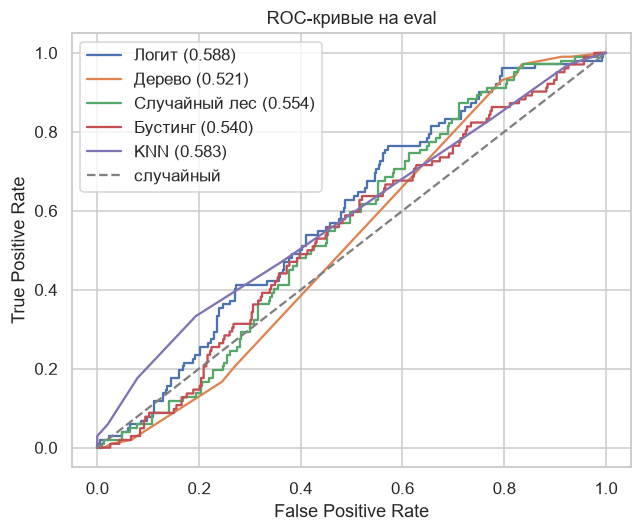

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, proba in probas_eval.items():
    fpr, tpr, _ = roc_curve(y_eval, proba)
    auc = roc_auc_score(y_eval, proba)
    ax.plot(fpr, tpr, label=f"{name} ({auc:.3f})")
ax.plot([0, 1], [0, 1], color="gray", ls="--", label="случайный")
ax.set_title("ROC-кривые на eval")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
plt.tight_layout()
plt.show()

Лес тоже опирается на доход; остальные признаки слабые. Слева встроенная важность леса (`feature_importances_`): она распределена почти поровну между непрерывными признаками. Так она устроена — признаки с большим числом значений чаще идут в разбиения, даже если сигнала в них нет. Справа проверка на eval: перемешиваем один признак и смотрим, насколько упал ROC-AUC. Заметно падает только без дохода, остальные признаки дают изменения в пределах шума — лес использует их, чтобы подстроиться под train. Это иллюстрация к уже обученной модели, не новая модель.

                  встроенная важность  падение ROC-AUC на eval   std
annual_income                   0.196                    0.056 0.020
customer_age                    0.126                    0.016 0.011
interest_rate                   0.179                    0.014 0.013
principal_amount                0.176                    0.014 0.015
term_months                     0.061                    0.005 0.006
product_2                       0.005                   -0.001 0.003
emp_2                           0.052                   -0.003 0.016
loan_to_income                  0.204                   -0.009 0.020


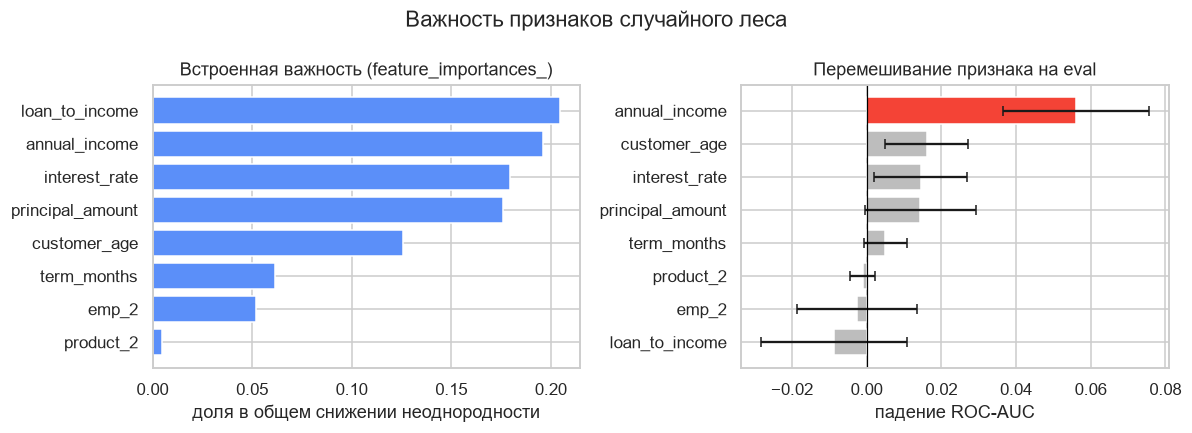

In [11]:
rf = fitted["Случайный лес"]
perm = permutation_importance(rf, X_eval_s, y_eval, scoring="roc_auc", n_repeats=30, random_state=42)
imp = pd.DataFrame({
    "встроенная важность": rf.feature_importances_,
    "падение ROC-AUC на eval": perm.importances_mean,
    "std": perm.importances_std,
}, index=feature_cols)
print(imp.sort_values("падение ROC-AUC на eval", ascending=False).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
o1 = imp.sort_values("встроенная важность")
axes[0].barh(o1.index, o1["встроенная важность"], color="#5B8FF9")
axes[0].set_title("Встроенная важность (feature_importances_)")
axes[0].set_xlabel("доля в общем снижении неоднородности")

o2 = imp.sort_values("падение ROC-AUC на eval")
axes[1].barh(o2.index, o2["падение ROC-AUC на eval"], xerr=o2["std"], capsize=3,
             color=["#F44336" if f == "annual_income" else "#BDBDBD" for f in o2.index])
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("Перемешивание признака на eval")
axes[1].set_xlabel("падение ROC-AUC")
plt.suptitle("Важность признаков случайного леса")
plt.tight_layout()
plt.show()

Лучшая по ROC-AUC на eval: Логит (все 8 признаков), F1-порог 0.17


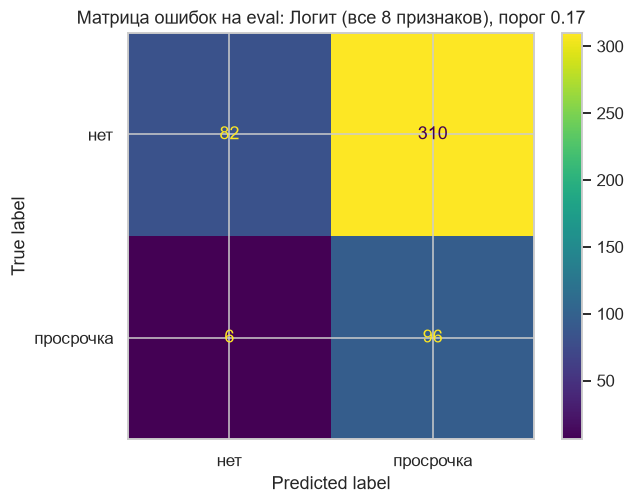

In [12]:
best_name = eval_05.iloc[0]["модель"]
best_model = fitted[best_name]
best_thr = eval_best.loc[eval_best["модель"] == best_name, "порог"].values[0]
print(f"Лучшая по ROC-AUC на eval: {best_name} (все 8 признаков), F1-порог {best_thr}")

cm = confusion_matrix(y_eval, (probas_eval[best_name] >= best_thr).astype(int))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["нет", "просрочка"])
disp.plot()
plt.title(f"Матрица ошибок на eval: {best_name} (все 8 признаков), порог {best_thr}")
plt.show()

### 4.1 Проверка: изменит ли вывод подбор гиперпараметров

В разделе 3 гиперпараметры заданы фиксированно. Проверим, изменит ли вывод подбор по кросс-валидации на train (`GridSearchCV`, 5 фолдов). Eval в подборе не участвует, только проверяет результат. Подобранные модели в выборе раздела 5 не участвуют — это проверка устойчивости вывода.

In [13]:
grids = {
    "Логит": (LogisticRegression(max_iter=2000, random_state=42),
              {"C": [0.01, 0.03, 0.1, 0.3, 1, 3]}),
    "Случайный лес": (RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
                      {"max_depth": [3, 4, 6], "min_samples_leaf": [10, 30, 60]}),
    "Бустинг": (GradientBoostingClassifier(subsample=0.8, random_state=42),
                {"n_estimators": [50, 150], "max_depth": [1, 2, 3], "learning_rate": [0.03, 0.1]}),
    "KNN": (KNeighborsClassifier(), {"n_neighbors": [15, 31, 61, 101]}),
}
gs_rows = []
for name, (est, grid) in grids.items():
    gs = GridSearchCV(est, grid, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42), scoring="roc_auc", n_jobs=-1)
    gs.fit(X_train_s, y_train)
    gs_rows.append({
        "модель": name,
        "лучшие параметры": gs.best_params_,
        "ROC-AUC CV (train)": gs.best_score_,
        "ROC-AUC eval (подобранная)": roc_auc_score(y_eval, gs.predict_proba(X_eval_s)[:, 1]),
        "ROC-AUC eval (раздел 4)": eval_05.loc[eval_05["модель"] == name, "ROC-AUC"].values[0],
    })
gs_table = pd.DataFrame(gs_rows)
print(gs_table.round(3).to_string(index=False))

       модель                                             лучшие параметры  ROC-AUC CV (train)  ROC-AUC eval (подобранная)  ROC-AUC eval (раздел 4)
        Логит                                                  {'C': 0.01}               0.563                       0.592                    0.588
Случайный лес                     {'max_depth': 3, 'min_samples_leaf': 10}               0.552                       0.559                    0.554
      Бустинг {'learning_rate': 0.03, 'max_depth': 1, 'n_estimators': 150}               0.552                       0.549                    0.540
          KNN                                          {'n_neighbors': 31}               0.571                       0.579                    0.583


Подбор вывод не меняет: ни одна подобранная модель не лучше логита. Для бустинга кросс-валидация выбрала деревья глубины 1 — самые простые, без взаимодействий признаков; для леса — неглубокие деревья. Сложные закономерности в данных не находятся, поэтому выигрывают простые модели.

## 5. Выбор модели

ROC-AUC на eval у пяти моделей лежит в диапазоне 0.52–0.59. Стандартная ошибка ROC-AUC на eval (494 кредита, около 100 просрочек) — около 0.033, считаем её по формуле Хэнли — Макнила. Смысл простой: если взять другие 494 кредита, ROC-AUC той же модели легко сдвинется на ±0.03.

Ни одна модель не лучше логистической регрессии: логит первый (0.588), KNN рядом (0.583), а случайный лес, бустинг и дерево ниже на 0.03–0.07, то есть на одну-две стандартные ошибки. На маленькой выборке со слабым сигналом сложные модели подстраиваются под шум train и выигрыша не дают.

Правило выбора: если лучшая модель не лучше логистической регрессии больше чем на стандартную ошибку, берём логит. Он интерпретируем, соответствует практике скоринга, а его коэффициенты можно объяснить бизнесу.

In [14]:
logit_auc = eval_05.loc[eval_05["модель"] == "Логит", "ROC-AUC"].values[0]
best_auc = eval_05.iloc[0]["ROC-AUC"]
se_eval = auc_se(best_auc, int(y_eval.sum()), int((1 - y_eval).sum()))
print(f"Лучший ROC-AUC: {best_auc:.3f} ({eval_05.iloc[0]['модель']})")
print(f"Логит ROC-AUC: {logit_auc:.3f}")
print(f"Разница: {best_auc - logit_auc:.3f}; стандартная ошибка ROC-AUC на eval около {se_eval:.3f}")

if best_auc - logit_auc < se_eval:
    chosen = "Логит"
    print("Разница меньше стандартной ошибки — берём логит: проще и объяснимее.")
else:
    chosen = eval_05.iloc[0]["модель"]
    print(f"Разница больше стандартной ошибки — берём {chosen}.")
print(f"Выбранная модель: {chosen}")

Лучший ROC-AUC: 0.588 (Логит)
Логит ROC-AUC: 0.588
Разница: 0.000; стандартная ошибка ROC-AUC на eval около 0.033
Разница меньше стандартной ошибки — берём логит: проще и объяснимее.
Выбранная модель: Логит


### 5.1 Выбор набора переменных

Модель выбрана — логистическая регрессия. Теперь выбираем набор переменных. Сравниваем полный набор, набор без суммы и отношения суммы к доходу (они вычисляются из суммы и дохода и дублируют друг друга) и несколько коротких наборов.

Качество оцениваем двумя способами: кросс-валидацией на train (5 частей) и на eval. Правило выбора: берём набор с лучшим средним ROC-AUC на кросс-валидации; eval служит проверкой, что он не хуже полного набора больше чем на стандартную ошибку.

In [15]:
feature_sets = {
    "все 8 признаков": feature_cols,
    "без суммы и loan_to_income": ["annual_income", "customer_age", "interest_rate", "term_months", "product_2", "emp_2"],
    "доход, возраст, занятость 2": ["annual_income", "customer_age", "emp_2"],
    "доход, занятость 2": ["annual_income", "emp_2"],
    "только доход": ["annual_income"],
    "без дохода": ["customer_age", "interest_rate", "term_months", "principal_amount", "loan_to_income", "product_2", "emp_2"],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fs_rows = []
for name, cols in feature_sets.items():
    idx = [feature_cols.index(c) for c in cols]
    # масштабирование внутри каждого фолда: валидационная часть не участвует в обучении StandardScaler
    pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
    cv_auc = cross_val_score(pipe, X_train[cols], y_train, cv=cv, scoring="roc_auc")
    m = LogisticRegression(max_iter=1000, random_state=42)
    m.fit(X_train_s[:, idx], y_train)
    fs_rows.append({
        "набор": name,
        "признаков": len(cols),
        "ROC-AUC CV (train)": cv_auc.mean(),
        "std по фолдам": cv_auc.std(),
        "ROC-AUC eval": roc_auc_score(y_eval, m.predict_proba(X_eval_s[:, idx])[:, 1]),
    })
fs_table = pd.DataFrame(fs_rows)
print(fs_table.to_string(index=False))

# правило выбора: лучший средний ROC-AUC на кросс-валидации по train;
# eval — проверка, что набор не хуже полного больше чем на стандартную ошибку
best_fs = fs_table.loc[fs_table["ROC-AUC CV (train)"].idxmax()]
full_eval = fs_table.loc[0, "ROC-AUC eval"]
se_full = auc_se(full_eval, int(y_eval.sum()), int((1 - y_eval).sum()))
if full_eval - best_fs["ROC-AUC eval"] <= se_full:
    final_set_name = best_fs["набор"]
else:
    final_set_name = "все 8 признаков"
print(f"\nСтандартная ошибка ROC-AUC на eval около {se_full:.3f}")
print(f"Выбранный набор: {final_set_name}")

                      набор  признаков  ROC-AUC CV (train)  std по фолдам  ROC-AUC eval
            все 8 признаков          8               0.544          0.064         0.588
 без суммы и loan_to_income          6               0.547          0.063         0.585
доход, возраст, занятость 2          3               0.573          0.060         0.577
         доход, занятость 2          2               0.575          0.062         0.564
               только доход          1               0.535          0.049         0.589
                 без дохода          7               0.504          0.037         0.578

Стандартная ошибка ROC-AUC на eval около 0.033
Выбранный набор: доход, занятость 2


Без дохода сигнала нет; различия между наборами меньше разброса по фолдам. Отрезки на синих столбцах — разброс ROC-AUC между пятью фолдами кросс-валидации.

Жёлтые столбцы показывают, насколько шумна одна оценка на eval. Набор «без дохода» на eval даёт 0.578, а «только доход» — 0.589, хотя на кросс-валидации у них 0.504 и 0.535. Одна оценка на 494 строках скачет сильнее, чем среднее по пяти фолдам на train, поэтому набор выбирается по кросс-валидации, а eval служит проверкой.

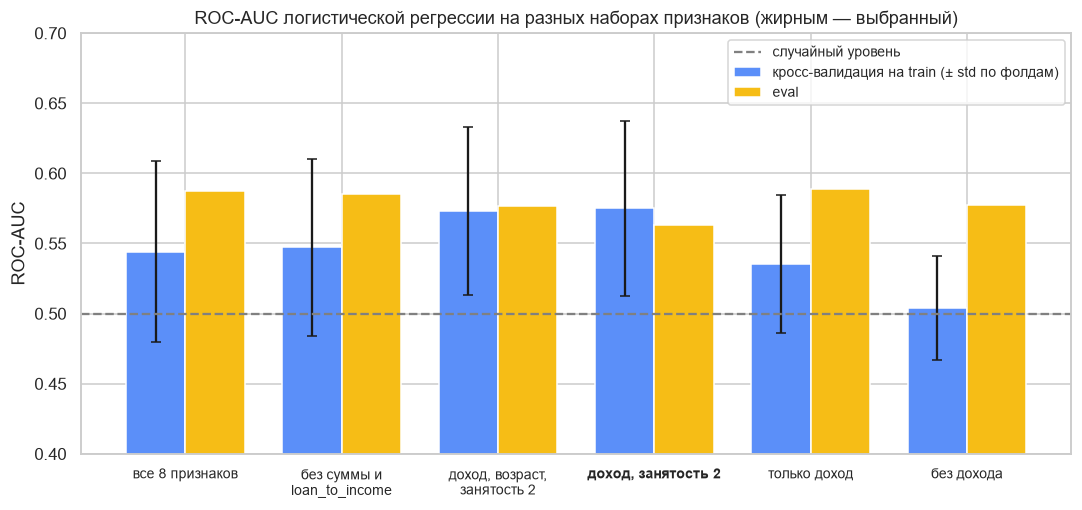

In [16]:
import textwrap

fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(fs_table))
wdt = 0.38
ax.bar(x - wdt / 2, fs_table["ROC-AUC CV (train)"], wdt, yerr=fs_table["std по фолдам"], capsize=3,
       color="#5B8FF9", edgecolor="white", label="кросс-валидация на train (± std по фолдам)")
ax.bar(x + wdt / 2, fs_table["ROC-AUC eval"], wdt, color="#F6BD16", edgecolor="white", label="eval")
ax.axhline(0.5, color="gray", ls="--", label="случайный уровень")
ax.set_xticks(x)
ax.set_xticklabels([textwrap.fill(s, 19) for s in fs_table["набор"]], fontsize=9)
for lbl in ax.get_xticklabels():
    if lbl.get_text().replace("\n", " ") == final_set_name:
        lbl.set_fontweight("bold")
ax.set_ylim(0.40, 0.70)
ax.set_title("ROC-AUC логистической регрессии на разных наборах признаков (жирным — выбранный)")
ax.set_ylabel("ROC-AUC")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

**Что видно из таблицы.** Разница между наборами меньше разброса по фолдам (std около 0.06), поэтому надёжно различить их нельзя. Но два вывода устойчивы. Без дохода кросс-валидационный ROC-AUC около 0.50, то есть остальные признаки без дохода сигнала не дают. Доход и статус занятости 2 — единственные переменные, на которых держится качество.

Выбран набор «доход, занятость 2»: лучший средний ROC-AUC на кросс-валидации (0.575) при двух признаках вместо восьми. На eval он даёт 0.564, что ниже полного набора (0.588) на 0.024 — меньше стандартной ошибки 0.033. Опираемся на кросс-валидацию, а не на eval: пять оценок по 1481 строке устойчивее одной оценки на 494.

#### Проверка альтернатив: флаг дохода и отрасль

Две альтернативы, которые напрашиваются из аттестации 1. Первая — доход флагом «верхний квартиль» вместо линейного дохода: по WoE в аттестации 1 выделялась только верхняя группа. Вторая — добавить отрасль: в аттестации 1 у неё IV 0.050. Отрасль проверяем двумя способами: каждая отрасль — свой флаг, и три корзины по доле просрочки. Всё подбирается только по train (порог квартиля, корзины), масштабирование — внутри каждого фолда, eval — проверка.

In [17]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def logit_pipe():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))


def cv_and_eval(model, A_train, A_eval):
    scores = cross_val_score(model, A_train, y_train, cv=cv5, scoring="roc_auc")
    model.fit(A_train, y_train)
    return scores.mean(), scores.std(), roc_auc_score(y_eval, model.predict_proba(A_eval)[:, 1])


alt_rows = []
base = ["annual_income", "emp_2"]

# 1) итоговый набор
alt_rows.append(("доход линейно + занятость 2 (выбранный)",
                 *cv_and_eval(logit_pipe(), X_train[base], X_eval[base])))

# 2) флаг верхнего квартиля дохода вместо линейного дохода; порог считается только по train
q75_train = X_train["annual_income"].quantile(0.75)


def with_flag(X):
    return pd.DataFrame({"high_income": (X["annual_income"] >= q75_train).astype(int), "emp_2": X["emp_2"]})


alt_rows.append(("флаг верхнего квартиля дохода + занятость 2",
                 *cv_and_eval(logit_pipe(), with_flag(X_train), with_flag(X_eval))))

# 3) отрасль: каждая отрасль — свой флаг, пропуск — отдельная категория
ind_train = df.loc[X_train.index, "industry_id"].fillna(-1).astype(int).astype(str).values
ind_eval = df.loc[X_eval.index, "industry_id"].fillna(-1).astype(int).astype(str).values
ohe_model = make_pipeline(
    ColumnTransformer([("num", StandardScaler(), base),
                       ("ind", OneHotEncoder(handle_unknown="ignore"), ["industry"])]),
    LogisticRegression(max_iter=1000, random_state=42),
)
alt_rows.append((f"+ отрасль: {len(set(ind_train))} флагов",
                 *cv_and_eval(ohe_model, X_train[base].assign(industry=ind_train),
                              X_eval[base].assign(industry=ind_eval))))


# 4) отрасль тремя корзинами по доле просрочки
def basket_map(y, ind):
    rate = pd.Series(np.asarray(y)).groupby(ind).mean().sort_values()
    return dict(zip(rate.index, pd.qcut(rate.rank(method="first"), 3, labels=[0, 1, 2]).astype(int)))


def with_baskets(X, ind, mapping):
    b = pd.Series(ind).map(mapping).fillna(1).values   # незнакомая отрасль — в среднюю корзину
    return np.c_[X[base].values, (b == 0).astype(int), (b == 2).astype(int)]


# 4а) корзины по всему train, затем CV: валидационная часть каждого фолда уже «видела» свой таргет
map_all = basket_map(y_train, ind_train)
naive = cross_val_score(logit_pipe(), with_baskets(X_train, ind_train, map_all), y_train,
                        cv=cv5, scoring="roc_auc")

# 4б) корректно: корзины строятся заново внутри каждого фолда, только по его обучающей части
fold_auc = []
for tr_i, va_i in cv5.split(X_train, y_train):
    mp = basket_map(y_train.iloc[tr_i], ind_train[tr_i])
    m = logit_pipe().fit(with_baskets(X_train.iloc[tr_i], ind_train[tr_i], mp), y_train.iloc[tr_i])
    fold_auc.append(roc_auc_score(
        y_train.iloc[va_i],
        m.predict_proba(with_baskets(X_train.iloc[va_i], ind_train[va_i], mp))[:, 1]))

m = logit_pipe().fit(with_baskets(X_train, ind_train, map_all), y_train)
eval_baskets = roc_auc_score(y_eval, m.predict_proba(with_baskets(X_eval, ind_eval, map_all))[:, 1])
alt_rows.append(("+ отрасль 3 корзинами (корзины по всему train)", naive.mean(), naive.std(), eval_baskets))
alt_rows.append(("+ отрасль 3 корзинами (корзины внутри фолда)", np.mean(fold_auc), np.std(fold_auc), eval_baskets))

alt_table = pd.DataFrame(alt_rows, columns=["вариант", "ROC-AUC CV (train)", "std по фолдам", "ROC-AUC eval"])
print(f"Порог верхнего квартиля дохода (по train): {q75_train:,.0f}\n")
print(alt_table.round(3).to_string(index=False))

Порог верхнего квартиля дохода (по train): 2,713,984

                                       вариант  ROC-AUC CV (train)  std по фолдам  ROC-AUC eval
       доход линейно + занятость 2 (выбранный)               0.575          0.062         0.564
   флаг верхнего квартиля дохода + занятость 2               0.579          0.040         0.561
                          + отрасль: 13 флагов               0.568          0.059         0.552
+ отрасль 3 корзинами (корзины по всему train)               0.602          0.065         0.537
  + отрасль 3 корзинами (корзины внутри фолда)               0.569          0.054         0.537


**Почему доход линейно, а не флагом.** Флаг верхнего квартиля (порог по train — 2.71 млн) даёт то же качество: CV 0.579 против 0.575, eval 0.561 против 0.564. Разница намного меньше разброса по фолдам и стандартной ошибки. Оставлен линейный доход: в логите он тоже отражает главное — у высокого дохода риск ниже.

**Почему нет отрасли.** Отрасль не помогает ни в каком виде. Тринадцать флагов (12 отраслей и пропуск) снижают качество: CV 0.568, eval 0.552. Три корзины по доле просрочки выглядят хорошо только при некорректной проверке. Если корзины построить по всему train, CV поднимается до 0.602: корзины подобраны по таргету тех же строк, на которых потом считается CV, — это утечка внутри кросс-валидации. Если строить корзины заново внутри каждого фолда, CV 0.569 — ниже, чем без отрасли, а на eval 0.537. Группы, подобранные по таргету, на новые данные не переносятся, поэтому отрасль в модель не включена.

Коэффициенты итоговой модели ниже. Для дамми (статус занятости 2) множитель шансов пересчитан на переход 0 → 1, для дохода — на рост на одно стандартное отклонение.

In [18]:
final_features = feature_sets[final_set_name]
idx_final = [feature_cols.index(c) for c in final_features]

final_model = LogisticRegression(max_iter=1000, random_state=42)
final_model.fit(X_train_s[:, idx_final], y_train)
proba_eval_final = final_model.predict_proba(X_eval_s[:, idx_final])[:, 1]

# множитель шансов: для числовых признаков — на 1 стандартное отклонение, для дамми — переход 0 -> 1
w = final_model.coef_[0]
is_dummy = np.array([c in ("product_2", "emp_2") for c in final_features])
sd = scaler.scale_[idx_final]
coef_table = pd.DataFrame({
    "признак": final_features,
    "коэффициент (признаки стандартизованы)": w,
    "множитель шансов": np.where(is_dummy, np.exp(w / sd), np.exp(w)),
    "на что": np.where(is_dummy, "переход 0 → 1", "рост на 1 σ"),
})
print(coef_table.to_string(index=False))

      признак  коэффициент (признаки стандартизованы)  множитель шансов        на что
annual_income                                  -0.250             0.779   рост на 1 σ
        emp_2                                   0.236             2.118 переход 0 → 1


### 5.2 Порог и матрица ошибок итоговой модели на eval

Порог выбирается по F1 на eval (сетка 0.10–0.49). Вероятности лежат около доли класса (≈21%), поэтому стандартный порог 0.5 никого не помечает. F1-оптимальный порог (0.18) помечает большинство кредитов: около 79% на eval (на forecast — 74%, раздел 6). Recall высокий, precision около 0.24. Формально это лучше правила «ставить 1 всем» (F1 0.378 против 0.342), но как фильтр такой порог почти ничего не отсеивает.

В банковских терминах качество ранжирования часто выражают через Gini = 2 × ROC-AUC − 1: для итоговой модели на eval это 2 × 0.5635 − 1 ≈ 0.127 (ROC-AUC до округления — 0.5635).

Метрики на eval оптимистичны: порог подобран на тех же данных.

модель        Логит, доход, занятость 2
порог                             0.180
ROC-AUC                           0.564
Accuracy                          0.381
Precision                         0.238
Recall                            0.912
F1                                0.378
помечено 1                          390
Gini = 2 × ROC-AUC − 1 = 2 × 0.5635 − 1 = 0.127

Ориентиры на eval: F1 «ставить 1 всем» = 0.342; accuracy «всем 0» = 0.794


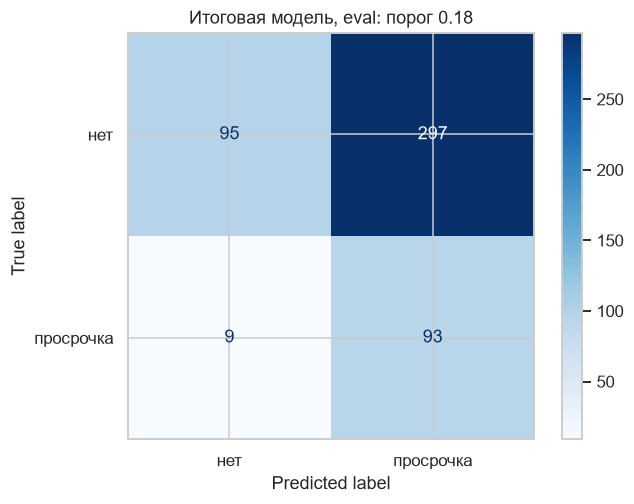

In [19]:
thresholds = np.round(np.arange(0.10, 0.50, 0.01), 2)
f1s = [f1_score(y_eval, (proba_eval_final >= t).astype(int), zero_division=0) for t in thresholds]
final_thr = thresholds[int(np.argmax(f1s))]

res = metrics_at(f"Логит, {final_set_name}", y_eval, proba_eval_final, final_thr)
print(pd.Series(res).to_string())
print(f"Gini = 2 × ROC-AUC − 1 = 2 × {res['ROC-AUC']:.4f} − 1 = {2 * res['ROC-AUC'] - 1:.3f}")
print(f"\nОриентиры на eval: F1 «ставить 1 всем» = {f1_score(y_eval, np.ones_like(y_eval)):.3f}; "
      f"accuracy «всем 0» = {1 - y_eval.mean():.3f}")

cm = confusion_matrix(y_eval, (proba_eval_final >= final_thr).astype(int))
ConfusionMatrixDisplay(cm, display_labels=["нет", "просрочка"]).plot(cmap="Blues")
plt.title(f"Итоговая модель, eval: порог {final_thr}")
plt.show()

Порог по F1 помечает большую часть заявок: выигрыш над правилом «ставить 1 всем» небольшой.

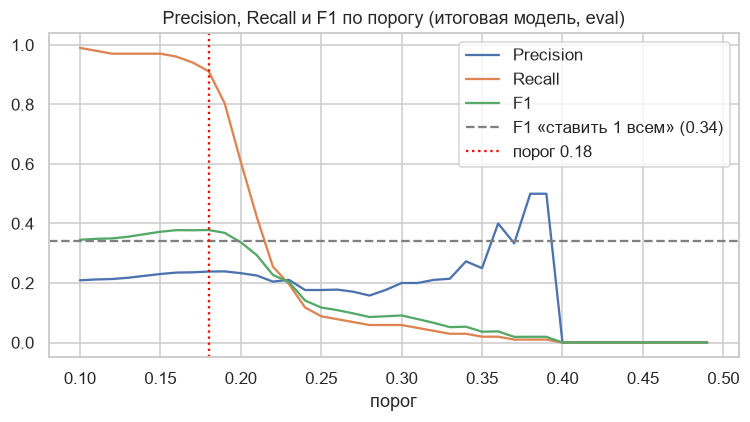

In [20]:
prec = [precision_score(y_eval, (proba_eval_final >= t).astype(int), zero_division=0) for t in thresholds]
rec  = [recall_score(y_eval, (proba_eval_final >= t).astype(int), zero_division=0) for t in thresholds]
f1_all = f1_score(y_eval, np.ones_like(y_eval))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thresholds, prec, label="Precision")
ax.plot(thresholds, rec, label="Recall")
ax.plot(thresholds, f1s, label="F1")
ax.axhline(f1_all, color="gray", ls="--", label=f"F1 «ставить 1 всем» ({f1_all:.2f})")
ax.axvline(final_thr, color="red", ls=":", label=f"порог {final_thr}")
ax.set_title("Precision, Recall и F1 по порогу (итоговая модель, eval)")
ax.set_xlabel("порог")
ax.legend()
plt.tight_layout()
plt.show()

PR-кривая показывает, какую точность (precision) модель держит при каждой полноте (recall). У случайной модели точность везде равна доле просрочек, поэтому серый пунктир — это уровень угадывания. Площадь под PR-кривой (AP, average precision) у итоговой модели лишь немного выше этого уровня: сигнал слабый. Красная точка — выбранный порог 0.18.

AP итоговой модели на eval: 0.232; доля просрочек (уровень случайной модели): 0.206


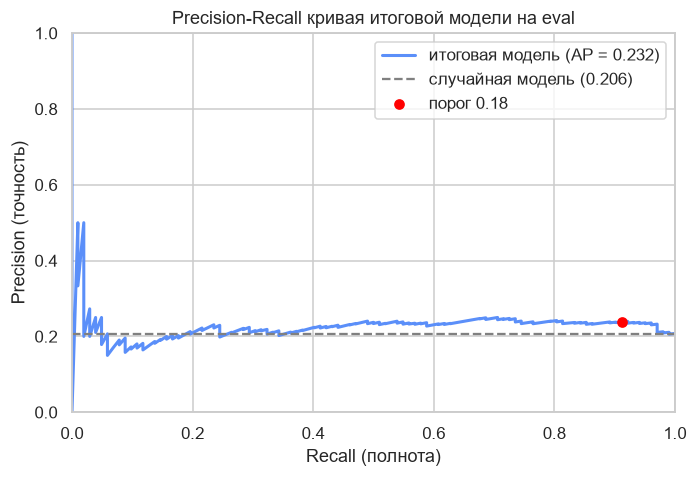

In [21]:
pr_prec, pr_rec, _ = precision_recall_curve(y_eval, proba_eval_final)
ap_final = average_precision_score(y_eval, proba_eval_final)
print(f"AP итоговой модели на eval: {ap_final:.3f}; доля просрочек (уровень случайной модели): {y_eval.mean():.3f}")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(pr_rec, pr_prec, lw=2, color="#5B8FF9", label=f"итоговая модель (AP = {ap_final:.3f})")
ax.axhline(y_eval.mean(), color="gray", ls="--", label=f"случайная модель ({y_eval.mean():.3f})")
ax.scatter([res["Recall"]], [res["Precision"]], color="red", zorder=3, label=f"порог {final_thr}")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("Precision-Recall кривая итоговой модели на eval")
ax.set_xlabel("Recall (полнота)")
ax.set_ylabel("Precision (точность)")
ax.legend()
plt.tight_layout()
plt.show()

Доход снижает шансы просрочки, статус занятости 2 повышает.

Множитель 2.1 у статуса занятости 2 — это отношение шансов при одинаковом доходе, а не «просрочка в 2 раза чаще». По сырым долям просрочка выше в 1.47 раза (28.9% против 19.6%). Модель даёт больше, потому что у статуса 2 медианный доход выше (раздел 1.1), а высокий доход сам снижает риск и частично маскирует риск статуса.

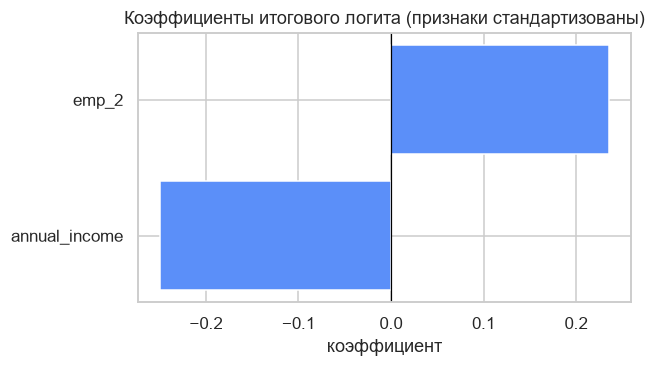

In [22]:
fig, ax = plt.subplots(figsize=(6, 3.5))
order = coef_table.sort_values("коэффициент (признаки стандартизованы)")
ax.barh(order["признак"], order["коэффициент (признаки стандартизованы)"], color="#5B8FF9")
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Коэффициенты итогового логита (признаки стандартизованы)")
ax.set_xlabel("коэффициент")
plt.tight_layout()
plt.show()

### 5.3 Горизонт наблюдения: диагностика по рекомендации преподавателя

Проверяем признак горизонта наблюдения `payments_cnt` — сколько платежей по кредиту уже прошло. Это **не признак модели**: при выдаче кредита он неизвестен, это утечка, и ни в одну модель для выбора или прогноза он не входит. Ячейка показывает потолок качества, если бы горизонт наблюдения был известен заранее. Считаем на тех же eval-строках.

In [23]:
# Диагностика, не модель: payments_cnt при выдаче неизвестен и ни в одну модель не входит
pay_eval = df.loc[X_eval.index, "payments_cnt"]
auc_pay = roc_auc_score(y_eval, pay_eval)
print(f"payments_cnt (горизонт наблюдения, утечка): ROC-AUC на eval {auc_pay:.3f}")
print(f"Лучшая модель на признаках при выдаче ({best_name}, 8 признаков): {best_auc:.3f}")
print(f"Итоговая модель (доход, занятость 2): {roc_auc_score(y_eval, proba_eval_final):.3f}")
print(f"Стандартная ошибка ROC-AUC на eval около {se_eval:.3f}")

payments_cnt (горизонт наблюдения, утечка): ROC-AUC на eval 0.638
Лучшая модель на признаках при выдаче (Логит, 8 признаков): 0.588
Итоговая модель (доход, занятость 2): 0.564
Стандартная ошибка ROC-AUC на eval около 0.033


Просрочка растёт с числом прошедших платежей — это длина наблюдения, а не признак заёмщика. Красная линия — формула из аттестации 1: каждый платёж независимо оказывается просроченным с одной и той же вероятностью `p`, признаков заёмщика в ней нет. Она идёт вплотную к фактическим точкам. Считаем по train и eval; таргет forecast не используется. Серые числа над точками — сколько кредитов в группе.

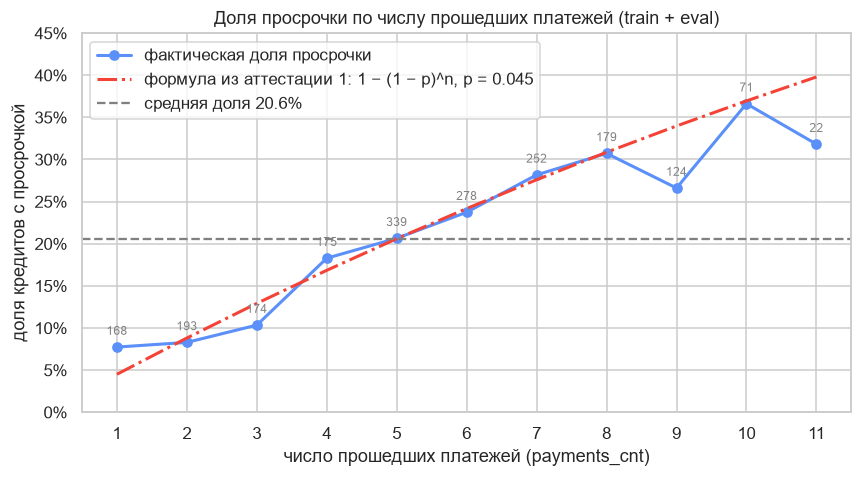

In [24]:
pay_obs = df.loc[X_train.index.append(X_eval.index)]          # train + eval, таргет forecast не трогаем
rate_by_pay = pay_obs.groupby("payments_cnt")["is_overdue"].agg(["mean", "count"])
p_late = pay_obs["late_cnt"].sum() / pay_obs["payments_cnt"].sum()
n_pay = rate_by_pay.index.values

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(n_pay, rate_by_pay["mean"], marker="o", lw=2, color="#5B8FF9", label="фактическая доля просрочки")
ax.plot(n_pay, 1 - (1 - p_late) ** n_pay, ls="-.", lw=2, color="#F44336",
        label=f"формула из аттестации 1: 1 − (1 − p)^n, p = {p_late:.3f}")
ax.axhline(pay_obs["is_overdue"].mean(), color="gray", ls="--",
           label=f"средняя доля {pay_obs['is_overdue'].mean():.1%}")
for xi, (m, cnt) in zip(n_pay, rate_by_pay.values):
    ax.annotate(f"{int(cnt)}", (xi, m), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=8, color="gray")
ax.set_xticks(n_pay)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, 0.45)
ax.set_title("Доля просрочки по числу прошедших платежей (train + eval)")
ax.set_xlabel("число прошедших платежей (payments_cnt)")
ax.set_ylabel("доля кредитов с просрочкой")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

Потолок качества задаёт горизонт наблюдения, недоступный при выдаче. Отрезки — ± одна стандартная ошибка ROC-AUC на eval.

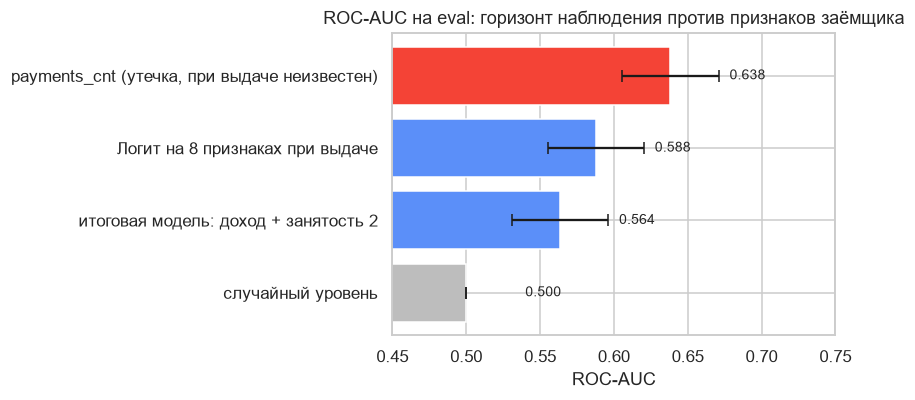

In [25]:
ceiling = pd.Series({
    "случайный уровень": 0.5,
    "итоговая модель: доход + занятость 2": roc_auc_score(y_eval, proba_eval_final),
    f"{best_name} на 8 признаках при выдаче": best_auc,
    "payments_cnt (утечка, при выдаче неизвестен)": auc_pay,
})

fig, ax = plt.subplots(figsize=(8, 3.8))
colors = ["#BDBDBD", "#5B8FF9", "#5B8FF9", "#F44336"]
xerr = [0, se_eval, se_eval, se_eval]
ax.barh(ceiling.index, ceiling.values, xerr=xerr, capsize=4, color=colors, edgecolor="white")
for yi, v in enumerate(ceiling.values):
    ax.text(v + 0.04, yi, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0.45, 0.75)
ax.set_title("ROC-AUC на eval: горизонт наблюдения против признаков заёмщика")
ax.set_xlabel("ROC-AUC")
plt.tight_layout()
plt.show()

Один технический признак — сколько платежей успело пройти — даёт ROC-AUC 0.638, выше любой модели на признаках, известных при выдаче (лучшая 0.588). Значит, заметная часть «сигнала» в цели — не свойства заёмщика, а время, в течение которого кредит наблюдался. При выдаче этого числа нет, поэтому в скоринг признак не входит, а потолок качества на признаках заёмщика остаётся низким. Учесть горизонт можно двумя способами: зафиксировать его в самой цели (рекомендация 6 в разделе 7, это следующий шаг на уровне SQL-витрины) или моделировать риск одного платежа — это сделано в разделе 5.4.

### 5.4 Горизонт наблюдения внутри модели

Признаки «из будущего» нельзя брать **входами** модели — при выдаче их нет. Но их можно использовать корректно — как **цель и экспозицию**. Каждый кредит — это `payments_cnt` платежей, из них `late_cnt` просрочены. Логистическая регрессия учится на уровне одного платежа: какова вероятность `q`, что очередной платёж будет просрочен, при данном доходе и статусе занятости. Входы модели — те же два признака итоговой модели; `late_cnt` и `payments_cnt` задают только цель и вес строки (`sample_weight`).

Тогда вероятность хотя бы одной просрочки за `n` платежей считается по формуле из аттестации 1: `1 − (1 − q)^n`. Срок `n` можно задать одинаковым для всех заявок — например, первые 6 платежей. Это бизнес-понятная величина. Таргет eval и forecast здесь в обучении не участвует.

In [26]:
# Модель на уровне платежа: входы — только признаки при выдаче.
# late_cnt и payments_cnt train задают цель и вес строки, входами модели они не являются.
n_train = df.loc[X_train.index, "payments_cnt"].values
late_train = df.loc[X_train.index, "late_cnt"].values
Xp = X_train_s[:, idx_final]

X_pay = np.vstack([Xp, Xp])                           # каждый кредит дважды:
y_pay = np.r_[np.ones(len(Xp)), np.zeros(len(Xp))]    # строка «просроченные платежи» и строка «платежи вовремя»
w_pay = np.r_[late_train, n_train - late_train]       # вес строки — сколько таких платежей

pay_model = LogisticRegression(max_iter=1000, random_state=42)
pay_model.fit(X_pay, y_pay, sample_weight=w_pay)
q_eval = pay_model.predict_proba(X_eval_s[:, idx_final])[:, 1]
q_forecast = pay_model.predict_proba(X_forecast_s[:, idx_final])[:, 1]

print(f"Платежей в train: {n_train.sum()}, просрочено: {late_train.sum()} ({late_train.sum() / n_train.sum():.2%})")
print(pd.DataFrame({
    "признак": final_features,
    "коэффициент: модель на уровне кредита": final_model.coef_[0],
    "коэффициент: модель на уровне платежа": pay_model.coef_[0],
}).round(3).to_string(index=False))

corr_n = pd.Series({c: np.corrcoef(X_train[c], n_train)[0, 1] for c in feature_cols})
print(f"\nСвязь числа платежей с признаками заёмщика (train): максимальная |r| = {corr_n.abs().max():.3f}")

print(f"\nROC-AUC на eval: ранжирование по q {roc_auc_score(y_eval, q_eval):.3f}, "
      f"итоговая модель {roc_auc_score(y_eval, proba_eval_final):.3f}")
n_eval = df.loc[X_eval.index, "payments_cnt"].values
auc_pay_plus = roc_auc_score(y_eval, 1 - (1 - q_eval) ** n_eval)
print(f"С учётом фактического горизонта (только для анализа, при выдаче недоступно): "
      f"только payments_cnt {auc_pay:.3f}, payments_cnt + признаки заёмщика {auc_pay_plus:.3f}")

p6_forecast = 1 - (1 - q_forecast) ** 6
print(f"\nForecast: вероятность хотя бы одной просрочки за первые 6 платежей — "
      f"в среднем {p6_forecast.mean():.1%}, от {p6_forecast.min():.1%} до {p6_forecast.max():.1%}")
print(f"Средний срок наблюдения в train: {n_train.mean():.1f} платежа — к нему относится вероятность итоговой модели")

Платежей в train: 7745, просрочено: 355 (4.58%)
      признак  коэффициент: модель на уровне кредита  коэффициент: модель на уровне платежа
annual_income                                 -0.250                                 -0.199
        emp_2                                  0.236                                  0.228

Связь числа платежей с признаками заёмщика (train): максимальная |r| = 0.068

ROC-AUC на eval: ранжирование по q 0.563, итоговая модель 0.564
С учётом фактического горизонта (только для анализа, при выдаче недоступно): только payments_cnt 0.638, payments_cnt + признаки заёмщика 0.651

Forecast: вероятность хотя бы одной просрочки за первые 6 платежей — в среднем 23.9%, от 11.5% до 50.1%
Средний срок наблюдения в train: 5.2 платежа — к нему относится вероятность итоговой модели


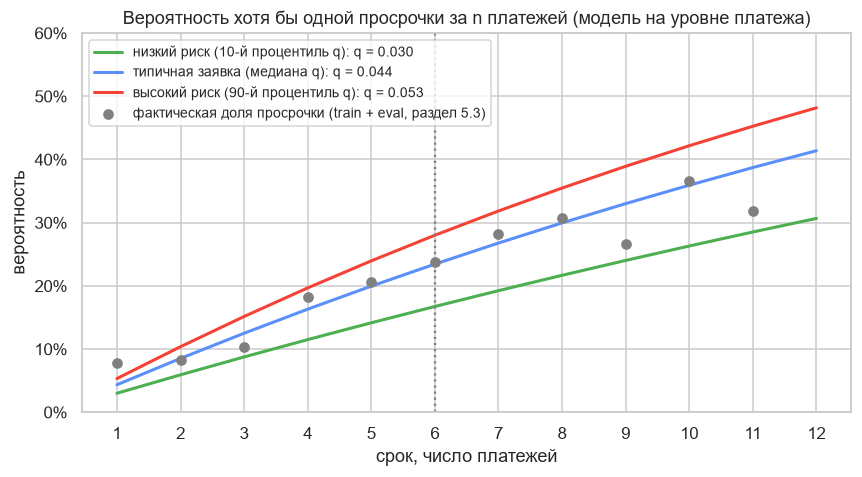

In [27]:
n_grid = np.arange(1, 13)
q_levels = {
    "низкий риск (10-й процентиль q)": np.quantile(q_forecast, 0.10),
    "типичная заявка (медиана q)": np.quantile(q_forecast, 0.50),
    "высокий риск (90-й процентиль q)": np.quantile(q_forecast, 0.90),
}
fig, ax = plt.subplots(figsize=(8, 4.5))
for (label, q), color in zip(q_levels.items(), ["#4CAF50", "#5B8FF9", "#F44336"]):
    ax.plot(n_grid, 1 - (1 - q) ** n_grid, lw=2, color=color, label=f"{label}: q = {q:.3f}")
ax.scatter(rate_by_pay.index, rate_by_pay["mean"], color="gray", zorder=3,
           label="фактическая доля просрочки (train + eval, раздел 5.3)")
ax.axvline(6, color="gray", ls=":")
ax.set_xticks(n_grid)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, 0.6)
ax.set_title("Вероятность хотя бы одной просрочки за n платежей (модель на уровне платежа)")
ax.set_xlabel("срок, число платежей")
ax.set_ylabel("вероятность")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

Коэффициенты модели на уровне платежа близки к итоговой модели: доход −0.199 против −0.250, статус занятости 2 +0.228 против +0.236. Ранжирование заявок то же: ROC-AUC на eval 0.563 против 0.564. Причина — число прошедших платежей почти не связано с признаками заёмщика (максимальная |r| = 0.068): при случайном разбиении горизонт добавляет в цель шум, но не искажает оценку признаков. К самому горизонту признаки заёмщика добавляют немного: 0.651 против 0.638 у одного `payments_cnt`, в пределах стандартной ошибки.

Практическая польза — вероятность за срок, одинаковый для всех заявок. За первые 6 платежей на forecast она в среднем 23.9%, от 11.5% до 50.1%. Вероятность итоговой модели (в среднем 0.20) так прочитать нельзя: она относится к сроку наблюдения в витрине, в среднем 5.2 платежа. Итоговая модель для ранжирования не меняется; вероятность за 6 платежей добавлена в файл прогнозов.

## 6. Прогноз на вторых 20% (forecast)

Модель получает только признаки. Для каждого кредита считаем вероятность просрочки, класс по порогу из раздела 5.2 и сегмент риска. Границы сегментов — квантили вероятностей на eval: нижние 50% — «низкий» риск, следующие 30% — «средний», верхние 20% — «высокий». Те же границы применяются к forecast, как это было бы при работе с новыми заявками.

Результат сохраняется в `forecast_predictions.csv`: `loan_id`, вероятность итоговой модели, класс по порогу, сегмент и вероятность хотя бы одной просрочки за первые 6 платежей (модель из раздела 5.4), по убыванию риска. Это рабочий список для отдела проверки.

In [28]:
X_forecast_blind = X_forecast.copy()          # таргета в этой таблице нет
proba_forecast = final_model.predict_proba(X_forecast_s[:, idx_final])[:, 1]
pred_forecast = (proba_forecast >= final_thr).astype(int)

# сегменты риска: границы — квантили вероятностей на eval (50% и 80%)
cuts = np.quantile(proba_eval_final, [0.5, 0.8])
seg_names = ["низкий", "средний", "высокий"]
seg_forecast = pd.Categorical(
    [seg_names[i] for i in np.digitize(proba_forecast, cuts)], categories=seg_names, ordered=True
)

forecast_result = X_forecast_blind.copy()
forecast_result["вероятность_просрочки"] = proba_forecast
forecast_result["прогноз_по_порогу"] = pred_forecast
forecast_result["сегмент_риска"] = seg_forecast

print(f"Прогнозов: {len(forecast_result)}")
print(f"Помечено по порогу {final_thr}: {pred_forecast.sum()} ({pred_forecast.mean():.1%})")
print(f"Средняя вероятность: {proba_forecast.mean():.3f}")
print(forecast_result["сегмент_риска"].value_counts().reindex(seg_names).to_string())

# файл для пользователей: кредит, вероятность, класс по порогу, сегмент — по убыванию риска
export = forecast_result[["вероятность_просрочки", "прогноз_по_порогу", "сегмент_риска"]].copy()
export.insert(0, "loan_id", df.loc[X_forecast.index, "loan_id"].values)
export["вероятность_просрочки"] = export["вероятность_просрочки"].round(4)
export["вероятность_за_6_платежей"] = p6_forecast.round(4)
export = export.sort_values("вероятность_просрочки", ascending=False)
export.to_csv("forecast_predictions.csv", index=False, encoding="utf-8-sig")
print(f"\nСохранено: forecast_predictions.csv ({len(export)} строк)")
forecast_result[["вероятность_просрочки"]].describe().round(3)

Прогнозов: 494
Помечено по порогу 0.18: 366 (74.1%)
Средняя вероятность: 0.202
сегмент_риска
низкий     260
средний    143
высокий     91

Сохранено: forecast_predictions.csv (494 строк)


,вероятность_просрочки
count,494.000
mean,0.202
std,0.053
min,0.085
25%,0.177
50%,0.200
75%,0.220
max,0.425


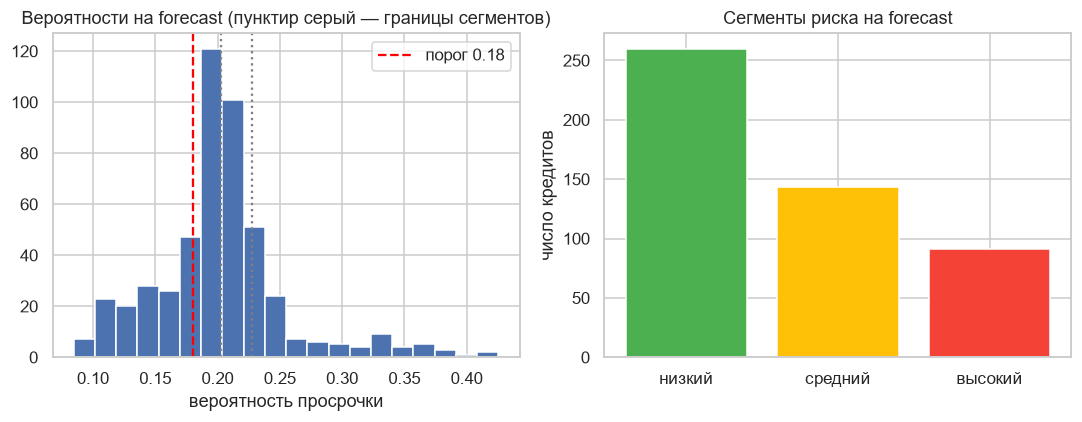

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(proba_forecast, bins=20, edgecolor="white")
axes[0].axvline(final_thr, color="red", ls="--", label=f"порог {final_thr}")
for cut in cuts:
    axes[0].axvline(cut, color="gray", ls=":")
axes[0].set_title("Вероятности на forecast (пунктир серый — границы сегментов)")
axes[0].set_xlabel("вероятность просрочки")
axes[0].legend()

seg_counts = forecast_result["сегмент_риска"].value_counts().reindex(seg_names)
axes[1].bar(seg_counts.index.astype(str), seg_counts.values, color=["#4CAF50", "#FFC107", "#F44336"])
axes[1].set_title("Сегменты риска на forecast")
axes[1].set_ylabel("число кредитов")
plt.tight_layout()
plt.show()

## 7. Рекомендации

Основа — прогнозы на forecast и фактические доли просрочек по сегментам на eval (там таргет известен).

In [30]:
# Фактические доли просрочек по сегментам на eval (таргет известен)
seg_eval = pd.Categorical(
    [seg_names[i] for i in np.digitize(proba_eval_final, cuts)], categories=seg_names, ordered=True
)
tab_eval = (pd.DataFrame({"сегмент": seg_eval, "просрочка": y_eval.values})
            .groupby("сегмент", observed=True)["просрочка"].agg(["count", "mean"]))
tab_eval["lift"] = tab_eval["mean"] / y_eval.mean()
tab_eval.columns = ["кредитов", "доля просрочек (факт)", "lift к средней"]
print("Eval, сегменты риска:")
print(tab_eval.to_string())

# Состав сегментов на forecast (таргета нет)
comp = forecast_result.groupby("сегмент_риска", observed=True).agg(
    кредитов=("прогноз_по_порогу", "size"),
    медианный_доход=("annual_income", "median"),
    доля_emp_2=("emp_2", "mean"),
)
print("\nForecast, состав сегментов:")
print(comp.to_string())

Eval, сегменты риска:
         кредитов  доля просрочек (факт)  lift к средней
сегмент                                                 
низкий        247                  0.178           0.863
средний       148                  0.243           1.178
высокий        99                  0.222           1.076

Forecast, состав сегментов:
               кредитов  медианный_доход  доля_emp_2
сегмент_риска                                       
низкий              260    2,544,618.780       0.000
средний             143    1,441,744.440       0.000
высокий              91      938,831.760       0.505


Только низкий сегмент устойчиво ниже средней доли просрочки.

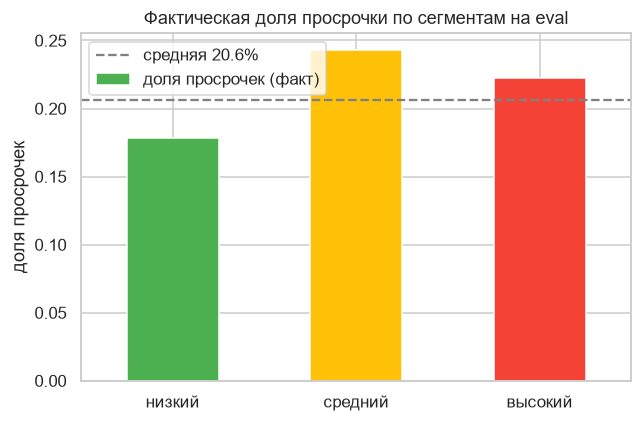

In [31]:
fig, ax = plt.subplots(figsize=(6, 4))
tab_eval["доля просрочек (факт)"].plot.bar(ax=ax, color=["#4CAF50", "#FFC107", "#F44336"], edgecolor="white")
ax.axhline(y_eval.mean(), color="gray", ls="--", label=f"средняя {y_eval.mean():.1%}")
ax.set_title("Фактическая доля просрочки по сегментам на eval")
ax.set_ylabel("доля просрочек")
ax.set_xlabel("")
ax.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Чтобы выбрать долю проверяемых заявок, полезно знать, сколько просрочек ловится, если проверять верхние k% списка по риску. Lift больше 1 — проверка эффективнее случайного выбора того же числа заявок.

In [32]:
def gains_table(y_true, proba, shares=(0.1, 0.2, 0.3, 0.5)):
    y_arr = np.asarray(y_true)
    order = np.argsort(-proba, kind="stable")
    rows = []
    for k in shares:
        top = int(round(k * len(y_arr)))
        caught = y_arr[order[:top]].sum()
        rows.append({
            "проверяем верхние": f"{k:.0%}",
            "заявок": top,
            "просрочек среди них": int(caught),
            "доля пойманных просрочек": caught / y_arr.sum(),
            "precision": caught / top,
            "lift": caught / top / y_arr.mean(),
        })
    return pd.DataFrame(rows)

gains_eval = gains_table(y_eval, proba_eval_final)
print(f"Eval, всего просрочек: {int(y_eval.sum())}")
print(gains_eval.round(3).to_string(index=False))

Eval, всего просрочек: 102
проверяем верхние  заявок  просрочек среди них  доля пойманных просрочек  precision  lift
              10%      49                    9                     0.088      0.184 0.890
              20%      99                   22                     0.216      0.222 1.076
              30%     148                   32                     0.314      0.216 1.047
              50%     247                   58                     0.569      0.235 1.137


Верхние 10% списка на eval не лучше случайного выбора (lift 0.89). Проверка верхних 20–30% ловит лишь немного больше пропорциональной доли (lift 1.05–1.08), верхней половины — 56.9% просрочек (lift 1.14). Модель надёжнее отделяет нижнюю половину, чем выделяет самый рискованный верх: в нижних 50% заявок 43.1% просрочек.

**Рекомендации для банка:**

1. **Не использовать F1-порог как фильтр.** При пороге 0.18 помечается 74% заявок на forecast (79% на eval): для ручной проверки это почти все. Практичнее работать с сегментами риска и выбирать долю проверяемых заявок по возможностям отдела. Ожидания при этом скромные: проверка верхней половины списка ловит 56.9% просрочек на eval, а верхние 10% на eval не лучше случайного выбора.
2. **Низкий риск — единственный сегмент, который воспроизводится.** Lift показывает, во сколько раз доля просрочки в сегменте отличается от средней. В низком сегменте на eval просрочка 17.8% при средней 20.6%, lift 0.86 — на 14% ниже средней, и это около половины заявок. Эффект небольшой (около 3 п.п.): решение об упрощённой процедуре для этого сегмента стоит принимать, сопоставив стоимость проверки со стоимостью просрочки. Различие между средним и высоким сегментами на eval ненадёжно (24.3% и 22.2%, lift 1.18 и 1.08), обещать точное ранжирование внутри верхней половины нельзя.
3. **Статус занятости 2.** Просрочка 28.9% против 19.6%, то есть в 1.47 раза чаще; при одинаковом доходе шансы просрочки выше примерно в 2.1 раза. Все такие заявки попадают в «высокий» сегмент: усилить проверку документов. Расшифровки статусов в витрине нет, смысл статуса нужно уточнить в банке.
4. **Доход.** Эффект сосредоточен в верхнем квартиле дохода (от 2.8 млн, просрочка 14.9%), в остальных трёх квартилях доля 21–24%. Плавной зависимости «чем выше, тем лучше» нет, поэтому жёсткие пороги по доходу не оправданы; высокий доход — довод в пользу упрощённой проверки.
5. **Ограничение модели.** ROC-AUC на eval 0.564 (Gini 0.127) при стандартной ошибке около 0.03: до случайного угадывания (0.5) примерно две ошибки. Модель — подсказка для ручной проверки, а не критерий отказа. Её нужно пересчитывать на свежих данных и следить за качеством после запуска. В учебной витрине нет данных кредитного бюро и полной долговой нагрузки (`loan_to_income` — только этот кредит к доходу); в реальном банке основной прирост качества дали бы именно они.
6. **Развитие проекта.** Значительная часть сигнала в цели — длина наблюдения, а не свойства заёмщика (раздел 5.3). Следующий шаг — пересобрать цель в SQL-витрине на фиксированном окне, например «просрочка среди первых трёх платежей» только для кредитов, у которых три платежа уже прошли. Тогда признаки заёмщика будут сравниваться на равных условиях. Уже сейчас для бизнеса понятнее вероятность за фиксированный срок из раздела 5.4 — она добавлена в файл прогнозов.

**Действия по сегментам** — дорогие действия направляются туда, где риск выше, дешёвые (СМС-напоминания) остаются для всех:

| Сегмент | Доля заявок | Что делает банк |
|---|---|---|
| низкий | около половины | упрощённая проверка и быстрое решение: клиент получает ответ быстрее, инспектор свободен для сложных заявок |
| средний | около 30% | обычный процесс проверки |
| высокий, в том числе все заявки со статусом занятости 2 | около 20% | проверка документов о доходе и занятости, предложение автоплатежа, дата платежа сразу после зарплаты, звонок перед первым платежом |

Запуск — пилотом: модель подсказывает, решение остаётся за инспектором. Через несколько месяцев сравнить просрочку по сегментам на новых выдачах и пересчитать модель.

**Чего модель не делает.** Она не предсказывает, кто из уже платящих клиентов просрочит в следующем месяце. Это отдельная задача — поведенческий скоринг действующих кредитов, где история платежей становится законным признаком, а действия другие: звонок до даты платежа, перенос даты, реструктуризация. Это следующий шаг проекта.

## 8. Контроль на forecast (в реальном применении недоступен)

В работе таргет forecast считался неизвестным: он не участвовал ни в обучении, ни в выборе модели, набора переменных и порога. В нашей витрине он известен, поэтому можно проверить, подтверждают ли фактические значения выводы с eval. Результаты контроля не используются для повторного выбора модели.

По результатам: ROC-AUC на forecast (0.572) близок к eval (0.564) — разница в пределах шума, слабый сигнал подтверждается. F1 при пороге 0.18 равен 0.355 против 0.339 у правила «ставить 1 всем». Низкий сегмент и на eval, и на forecast даёт 17–18% просрочек при средней 20.6% на eval и 20.4% на forecast: это различие воспроизводится. Порядок среднего и высокого сегментов на forecast верный (21.0% и 28.6%), на eval — обратный (24.3% и 22.2%), поэтому граница между ними ненадёжна.

In [33]:
auc_forecast = roc_auc_score(y_forecast_hidden, proba_forecast)
print(f"ROC-AUC: eval {roc_auc_score(y_eval, proba_eval_final):.3f}, forecast {auc_forecast:.3f}")
print(f"F1 при пороге {final_thr}: forecast {f1_score(y_forecast_hidden, pred_forecast):.3f}; "
      f"F1 «ставить 1 всем» {f1_score(y_forecast_hidden, np.ones_like(y_forecast_hidden)):.3f}")

tab_fc = (pd.DataFrame({"сегмент": forecast_result["сегмент_риска"].values, "просрочка": y_forecast_hidden.values})
          .groupby("сегмент", observed=True)["просрочка"].agg(["count", "mean"]))
tab_fc["lift"] = tab_fc["mean"] / y_forecast_hidden.mean()
tab_fc.columns = ["кредитов", "доля просрочек (факт)", "lift к средней"]
print("\nForecast, фактические доли по сегментам:")
print(tab_fc.to_string())

ROC-AUC: eval 0.564, forecast 0.572
F1 при пороге 0.18: forecast 0.355; F1 «ставить 1 всем» 0.339

Forecast, фактические доли по сегментам:
         кредитов  доля просрочек (факт)  lift к средней
сегмент                                                 
низкий        260                  0.173           0.847
средний       143                  0.210           1.026
высокий        91                  0.286           1.397


Низкий сегмент воспроизводится и на forecast (17–18%); порядок среднего и высокого сегментов на eval и forecast разный.

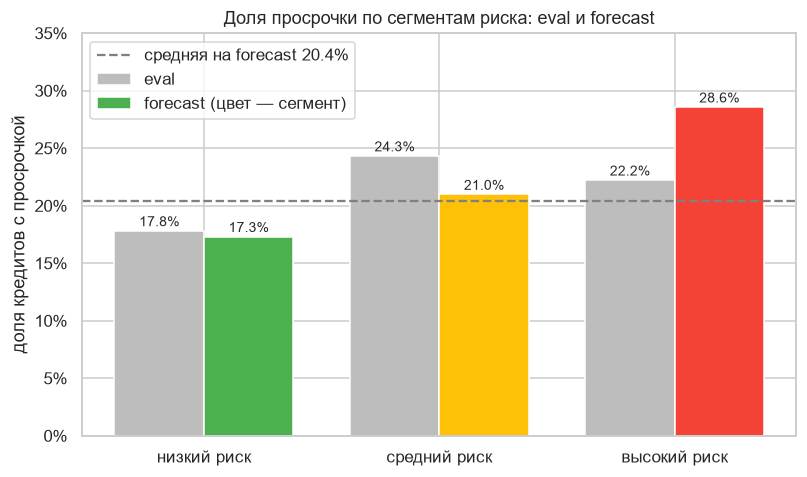

In [34]:
seg_compare = pd.DataFrame({
    "eval": tab_eval["доля просрочек (факт)"],
    "forecast": tab_fc["доля просрочек (факт)"],
}).reindex(seg_names)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
x = np.arange(len(seg_names))
wdt = 0.38
b1 = ax.bar(x - wdt / 2, seg_compare["eval"], wdt, color="#BDBDBD", edgecolor="white", label="eval")
b2 = ax.bar(x + wdt / 2, seg_compare["forecast"], wdt, color=["#4CAF50", "#FFC107", "#F44336"],
            edgecolor="white", label="forecast (цвет — сегмент)")
for bars in (b1, b2):
    for b in bars:
        ax.annotate(f"{b.get_height():.1%}", (b.get_x() + b.get_width() / 2, b.get_height()),
                    textcoords="offset points", xytext=(0, 3), ha="center", fontsize=9)
ax.axhline(y_forecast_hidden.mean(), color="gray", ls="--",
           label=f"средняя на forecast {y_forecast_hidden.mean():.1%}")
ax.set_xticks(x)
ax.set_xticklabels([f"{s} риск" for s in seg_names])
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, 0.35)
ax.set_title("Доля просрочки по сегментам риска: eval и forecast")
ax.set_ylabel("доля кредитов с просрочкой")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

Forecast, всего просрочек: 101
проверяем верхние  заявок  просрочек среди них  доля пойманных просрочек  precision  lift
              10%      49                   17                     0.168      0.347 1.697
              20%      99                   27                     0.267      0.273 1.334
              30%     148                   36                     0.356      0.243 1.190
              50%     247                   57                     0.564      0.231 1.129


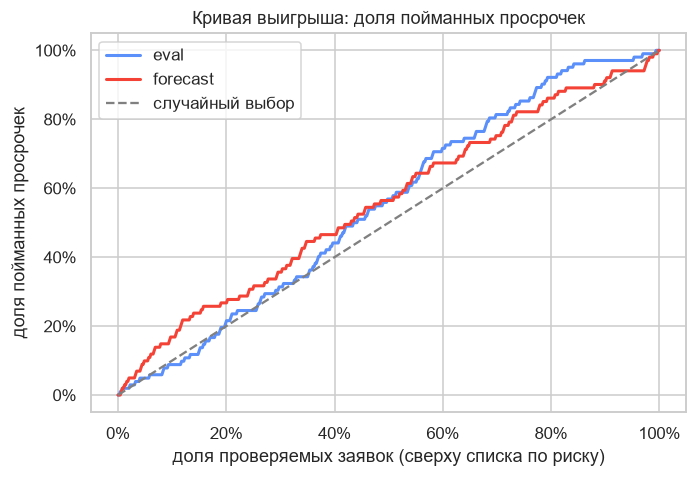

In [35]:
gains_fc = gains_table(y_forecast_hidden, proba_forecast)
print(f"Forecast, всего просрочек: {int(y_forecast_hidden.sum())}")
print(gains_fc.round(3).to_string(index=False))


def gains_curve(y_true, proba):
    y_arr = np.asarray(y_true)[np.argsort(-proba, kind="stable")]
    share_checked = np.arange(0, len(y_arr) + 1) / len(y_arr)
    share_caught = np.r_[0, np.cumsum(y_arr)] / y_arr.sum()
    return share_checked, share_caught


fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name, yy, pp, color in [("eval", y_eval, proba_eval_final, "#5B8FF9"),
                            ("forecast", y_forecast_hidden, proba_forecast, "#F44336")]:
    xs, ys = gains_curve(yy, pp)
    ax.plot(xs, ys, lw=2, color=color, label=name)
ax.plot([0, 1], [0, 1], color="gray", ls="--", label="случайный выбор")
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title("Кривая выигрыша: доля пойманных просрочек")
ax.set_xlabel("доля проверяемых заявок (сверху списка по риску)")
ax.set_ylabel("доля пойманных просрочек")
ax.legend()
plt.tight_layout()
plt.show()

На forecast верх списка сработал лучше: верхние 10% дают lift 1.70 против 0.89 на eval. Такой разброс на 49 заявках — шум, поэтому обещать точность на самом верху списка нельзя. На уровне половины списка результаты совпадают: 56.9% просрочек на eval и 56.4% на forecast.

## 9. Задача для нейронной сети

Для табличных данных стандартный подход — интерпретируемая модель (логит). Для демонстрации нейросетевого подхода обучен многослойный перцептрон (MLP: один скрытый слой из 16 нейронов, активация ReLU) на тех же 8 признаках, что и логит в разделе 4. Результат ниже: ROC-AUC 0.578 против 0.588 у логита на тех же признаках, разница внутри стандартной ошибки. Сеть собрана через `MLPClassifier` из sklearn: архитектура та же, что и в PyTorch, а код короче.

**Задача для нейросети на другом типе данных.** Классификация текста обращений клиентов (чат, колл-центр) по теме: жалоба, вопрос по кредиту, запрос на реструктуризацию. Польза: обращение сразу попадает в нужную команду. Рост запросов на реструктуризацию — возможный ранний сигнал проблем с платежами, который можно сопоставить со скорингом (это гипотеза, её нужно проверять на данных).

**Модель.** Базовая линия — TF-IDF и логистическая регрессия; нейросеть — предобученный трансформер для русского языка (например, rubert-tiny2), дообученный на размеченных обращениях. Метрика — macro-F1, то есть среднее F1 по темам: редкие темы весят столько же, сколько частые. Нужно несколько сотен размеченных обращений на класс. В витрине `loan_overdue_mart.csv` текстов нет, поэтому эту задачу на текущих данных реализовать нельзя — нужен отдельный датасет.

**Альтернатива по материалам курса — компьютерное зрение.** Классификация сканов документов кредитного досье: паспорт, справка о доходах, выписка по счёту, нечитаемый скан. Модель — свёрточная сеть, предобученная на ImageNet (ResNet или VGG), с дообучением последних слоёв на размеченных сканах (transfer learning). Предобученная сеть уже умеет выделять края, текстуры и формы, поэтому дообучению хватает нескольких сотен изображений на класс. Метрика — macro-F1 и доля сканов, отправленных на ручную проверку. Эта задача ближе к кредитному процессу, чем обращения: она автоматизирует проверку документов, которую рекомендация 3 предлагает усилить для статуса занятости 2. Изображений в витрине нет, поэтому реализация возможна только на отдельном датасете.

In [36]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(hidden_layer_sizes=(16,), max_iter=2000, random_state=42, tol=1e-4)
mlp.fit(X_train_s, y_train)
auc_mlp = roc_auc_score(y_eval, mlp.predict_proba(X_eval_s)[:, 1])
auc_logit = roc_auc_score(y_eval, fitted["Логит"].predict_proba(X_eval_s)[:, 1])
se_mlp = auc_se(auc_logit, int(y_eval.sum()), int((1 - y_eval).sum()))

print(f"MLP ROC-AUC на eval: {auc_mlp:.3f}")
print(f"Логит (все 8 признаков) ROC-AUC на eval: {auc_logit:.3f}")
diff = auc_mlp - auc_logit
if abs(diff) < se_mlp:
    verdict = "в пределах шума"
elif diff > 0:
    verdict = "MLP лучше логита"
else:
    verdict = "MLP хуже логита"
print(f"Разница {diff:+.3f} при стандартной ошибке около {se_mlp:.3f}: {verdict}.")

MLP ROC-AUC на eval: 0.578
Логит (все 8 признаков) ROC-AUC на eval: 0.588
Разница -0.010 при стандартной ошибке около 0.033: в пределах шума.


## 10. Итог

- **Место в процессе банка:** блок внутреннего скоринга по анкете для маршрутизации новых заявок по глубине проверки; окончательное решение принимает цепочка с данными бюро и долговой нагрузкой.
- **Задача:** бинарная классификация просрочки на момент выдачи; разбиение 60 / 20 / 20 соблюдено, таргет forecast не использовался до контрольного раздела.
- **Модель:** пять моделей сравнены на eval; ни одна сложная модель не лучше логита, дерево и бустинг ниже него. Подбор гиперпараметров по кросс-валидации (раздел 4.1) вывод не меняет. Выбрана логистическая регрессия как простая и объяснимая.
- **Набор переменных:** доход и статус занятости 2. Без дохода сигнала нет (кросс-валидационный ROC-AUC около 0.50). Флаг дохода вместо линейного дохода и отрасль проверены в разделе 5.1 — качество они не улучшают.
- **Качество:** ROC-AUC 0.564 на eval (Gini 0.127) и 0.572 на forecast при стандартной ошибке около 0.03 — сигнал слабый.
- **Горизонт наблюдения:** по рекомендации преподавателя проверили признак горизонта наблюдения (`payments_cnt`): он даёт более высокий ROC-AUC (0.638 против 0.588), но недоступен при выдаче, поэтому в скоринг не входит. Этим объясняется слабый сигнал на признаках заёмщика. Модель на уровне платежа (раздел 5.4) использует горизонт корректно — как цель и экспозицию: ранжирование то же, зато появляется вероятность за фиксированный срок (за 6 платежей в среднем 23.9%).
- **Порог:** F1-оптимальный порог 0.18 помечает около трёх четвертей заявок, поэтому для практики предложены сегменты риска.
- **Рекомендации:** модель — подсказка для ручной проверки: усилить проверку при статусе занятости 2, упростить для нижней половины по риску; автоматических отказов не делать. Прогнозы сохранены в `forecast_predictions.csv`.
- **Нейросеть:** MLP на 8 признаках даёт ROC-AUC 0.578 против 0.588 у логита — разница внутри стандартной ошибки. Предложены две задачи: классификация текста обращений (трансформер) и классификация сканов документов кредитного досье (ResNet или VGG с дообучением); для обеих нужен отдельный датасет.